# Optimization 3: feature selection with Particle Swarm Optimization (PSO)

**Question:** do you need all 45 features, or does a smaller subset work just as well? Fewer features means less to compute from Zeek, a faster model, and sometimes better generalisation.

**How PSO works:** a swarm of "particles" each holds a candidate feature subset (45 bits, where 1 means "use this feature"). Each particle remembers its own best subset, and the swarm remembers the best subset found by anyone. On every step, each particle is pulled toward its own best and the swarm's best, with some randomness. This is the **binary PSO** variant.

**Fitness (how a subset is scored):** train a small, fast Random Forest on the subset and measure its validation F1, minus a small penalty for each feature used (`ALPHA`), so smaller subsets win ties.

**Feasibility:** feasible, but it trains many small models (`N_PARTICLES x N_ITER`), so it runs on subsamples. Results vary between runs, so report the seed. At the end, XGBoost with all features is compared with XGBoost on the selected subset. Run after the preprocessing notebook.

## 1. Imports

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

FITNESS_TARGET = "multiclass"  # "multiclass" (macro F1, more sensitive) or "binary"
N_PARTICLES = 12
N_ITER = 15
FIT_TRAIN_ROWS = 20000         # subsamples used inside the search, to keep each evaluation fast
FIT_VAL_ROWS = 10000
ALPHA = 0.02                   # penalty for using all features (scaled by the share of features used)

W, C1, C2, VMAX = 0.7, 1.5, 1.5, 4.0   # PSO inertia, pull toward own best, pull toward swarm best, speed limit

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 3b. Helpers (same evaluation as every other notebook)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

## 4. Fitness function

In [5]:
def stratified_subset(y, n):
    if n >= len(y):
        return np.arange(len(y))
    idx, _ = train_test_split(np.arange(len(y)), train_size=n, stratify=y, random_state=SEED)
    return idx


y_fit_full = ym_train if FITNESS_TARGET == "multiclass" else yb_train
y_val_full = ym_val if FITNESS_TARGET == "multiclass" else yb_val
tr_idx = stratified_subset(y_fit_full, FIT_TRAIN_ROWS)
va_idx = stratified_subset(y_val_full, FIT_VAL_ROWS)
Xf_tr, yf_tr = X_train[tr_idx], y_fit_full[tr_idx]
Xf_va, yf_va = X_val[va_idx], y_val_full[va_idx]

cache = {}


def fitness(mask):
    """Returns (penalised fitness, plain F1) for a 0/1 mask over the features."""
    key = mask.tobytes()
    if key not in cache:
        cols = np.flatnonzero(mask)
        rf = RandomForestClassifier(n_estimators=40, max_depth=12, n_jobs=-1,
                                    class_weight="balanced_subsample", random_state=SEED)
        rf.fit(Xf_tr[:, cols], yf_tr)
        pred = rf.predict(Xf_va[:, cols])
        f1 = f1_score(yf_va, pred, average="macro") if FITNESS_TARGET == "multiclass" else f1_score(yf_va, pred)
        cache[key] = (f1 - ALPHA * len(cols) / n_features, f1)
    return cache[key]


all_features = np.ones(n_features, dtype=np.int8)
print("all features: F1 = %.4f" % fitness(all_features)[1])

all features: F1 = 0.6848


## 5. Run the swarm

In [6]:
rng = np.random.default_rng(SEED)
pos = (rng.random((N_PARTICLES, n_features)) < 0.5).astype(np.int8)
pos[0] = 1                                          # one particle starts with every feature
vel = rng.uniform(-1, 1, (N_PARTICLES, n_features))

pbest = pos.copy()
pbest_fit = np.array([fitness(p)[0] for p in pos])
g = int(pbest_fit.argmax())
gbest, gbest_fit = pbest[g].copy(), float(pbest_fit[g])

history = []
t0 = time.time()
for it in range(N_ITER):
    r1, r2 = rng.random(vel.shape), rng.random(vel.shape)
    vel = W * vel + C1 * r1 * (pbest - pos) + C2 * r2 * (gbest - pos)
    vel = np.clip(vel, -VMAX, VMAX)
    prob = 1.0 / (1.0 + np.exp(-vel))                # chance that each feature is switched on
    pos = (rng.random(vel.shape) < prob).astype(np.int8)
    for i in range(N_PARTICLES):
        if pos[i].sum() == 0:                        # a subset needs at least one feature
            pos[i, rng.integers(n_features)] = 1
        f = fitness(pos[i])[0]
        if f > pbest_fit[i]:
            pbest[i], pbest_fit[i] = pos[i].copy(), f
        if f > gbest_fit:
            gbest, gbest_fit = pos[i].copy(), float(f)
    history.append({"iteration": it + 1, "best fitness": gbest_fit,
                    "best F1": fitness(gbest)[1], "features used": int(gbest.sum())})
    print(f"iter {it + 1:2d}/{N_ITER}  fitness {gbest_fit:.4f}  F1 {history[-1]['best F1']:.4f}  features {int(gbest.sum())}  ({time.time() - t0:.0f}s)")

iter  1/15  fitness 0.6813  F1 0.6916  features 20  (2s)
iter  2/15  fitness 0.6813  F1 0.6916  features 20  (4s)
iter  3/15  fitness 0.6831  F1 0.6928  features 19  (6s)
iter  4/15  fitness 0.6833  F1 0.6951  features 23  (8s)
iter  5/15  fitness 0.6893  F1 0.6980  features 17  (11s)
iter  6/15  fitness 0.6915  F1 0.7028  features 22  (13s)
iter  7/15  fitness 0.6915  F1 0.7028  features 22  (15s)
iter  8/15  fitness 0.6953  F1 0.7040  features 17  (17s)
iter  9/15  fitness 0.6954  F1 0.7051  features 19  (19s)
iter 10/15  fitness 0.6954  F1 0.7051  features 19  (21s)
iter 11/15  fitness 0.6954  F1 0.7051  features 19  (23s)
iter 12/15  fitness 0.6954  F1 0.7051  features 19  (25s)
iter 13/15  fitness 0.6954  F1 0.7051  features 19  (28s)
iter 14/15  fitness 0.6954  F1 0.7051  features 19  (30s)
iter 15/15  fitness 0.6954  F1 0.7051  features 19  (32s)


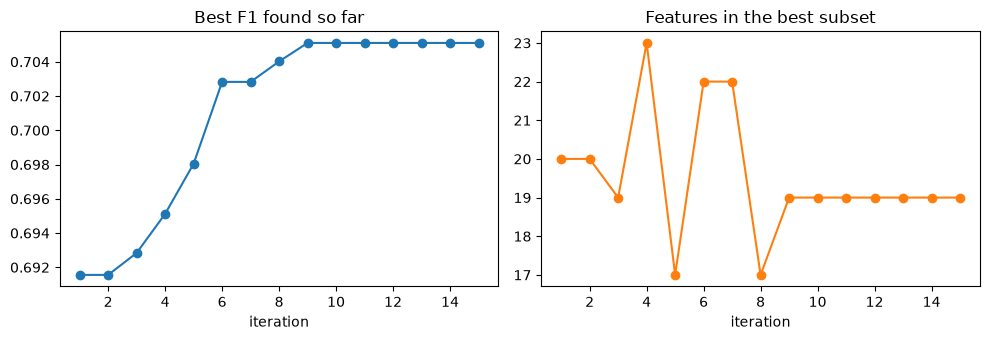

selected 19 of 39 features
kept:    ['sbytes', 'dbytes', 'spkts', 'dpkts', 'dload', 'smean', 'dmean', 'ct_srv_src', 'ct_src_ltm', 'ct_dst_src_ltm', 'proto_udp', 'proto_other', 'service_-', 'service_http', 'service_irc', 'service_snmp', 'service_other', 'state_reset', 'state_other']
dropped: ['dur', 'sload', 'is_sm_ips_ports', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'proto_tcp', 'proto_icmp', 'service_dns', 'service_smtp', 'service_ftp', 'service_ftp-data', 'service_ssh', 'service_pop3', 'service_ssl', 'service_dhcp', 'service_radius', 'state_ok', 'state_no_reply']


In [7]:
hist_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(hist_df["iteration"], hist_df["best F1"], marker="o")
axes[0].set_title("Best F1 found so far"); axes[0].set_xlabel("iteration")
axes[1].plot(hist_df["iteration"], hist_df["features used"], marker="o", color="tab:orange")
axes[1].set_title("Features in the best subset"); axes[1].set_xlabel("iteration")
plt.tight_layout(); plt.show()

selected = np.flatnonzero(gbest)
dropped = np.flatnonzero(gbest == 0)
print(f"selected {len(selected)} of {n_features} features")
print("kept:   ", [feature_names[i] for i in selected])
print("dropped:", [feature_names[i] for i in dropped])

## 6. Compare: all features vs the selected subset

Both use the same default XGBoost settings on the full training set, so the only difference is the features. Small differences are within normal run-to-run noise.

In [8]:
def eval_subset(cols, label):
    out = {"features": label, "n_features": len(cols)}
    t0 = time.time()
    m_bin = xgb.XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1, tree_method="hist",
                              n_jobs=-1, random_state=SEED).fit(X_train[:, cols], yb_train)
    m_multi = xgb.XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1, tree_method="hist",
                                n_jobs=-1, random_state=SEED).fit(X_train[:, cols], ym_train)
    out["train time (s)"] = round(time.time() - t0, 1)
    out["binary F1"] = f1_score(yb_val, m_bin.predict(X_val[:, cols]))
    out["multiclass macro F1"] = f1_score(ym_val, m_multi.predict(X_val[:, cols]), average="macro")
    out["ms per 1000 flows"] = ms_per_1000(lambda X: m_multi.predict(X[:, cols]), X_val)
    return out


compare = pd.DataFrame([eval_subset(np.arange(n_features), "all features"),
                        eval_subset(selected, "PSO subset")])
display(compare.round(4))

,features,n_features,train time (s),binary F1,multiclass macro F1,ms per 1000 flows
0,all features,39,11.5,0.9722,0.6516,5.1
1,PSO subset,19,7.7,0.9699,0.6725,5.6


## 7. Save the selected features

`selected_features.json` lists the kept columns. To use them, train a model on `X[:, selected_indices]`. In the live pipeline, apply the same column selection after `transform_with_artifacts()`.

In [9]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
(mdir / "selected_features.json").write_text(json.dumps({
    "selected_indices": [int(i) for i in selected],
    "selected_features": [feature_names[i] for i in selected],
    "dropped_features": [feature_names[i] for i in dropped],
    "fitness_target": FITNESS_TARGET, "alpha": ALPHA, "seed": SEED,
}, indent=2))
compare.to_csv(mdir / "pso_feature_selection_comparison.csv", index=False)
print("saved", mdir / "selected_features.json")

saved models\selected_features.json
